# Predicting the winner of Generation 2 OU Pokémon battles

**Task.** Given the full team of Player 1 (P1), the lead Pokémon of Player 2 (P2) and a summary of the first 30 turns of a battle, predict whether P1 wins. The metric is accuracy.

**Result.** The final model reaches about **69% accuracy** in 5-fold cross-validation, against 50% for a coin flip (the classes are perfectly balanced) and about 68% for our first baseline.

**Approach in one paragraph.** We turn every battle into about 250 numeric features plus about 1,700 sparse "bag-of-words" columns (which species and moves appear). The features describe the state of the battle after 30 turns: who has more HP left, who has lost more Pokémon, status conditions, type matchups, and so on. On top of that we add six groups of hand-crafted features based on how the game works: an estimate of P2's hidden Pokémon, win conditions such as boosted sweepers and Spikes, faints that the log seems to miss, P1's items, the shape of the HP lead over time, and a "player fingerprint" based on how often a given team wins. The final prediction blends a gradient-boosted tree model (LightGBM, 70%) with a regularised logistic regression (30%). Every modelling choice was made with cross-validation, taking care that no battle ever sees its own label.

### Contents
1. Setup and configuration
2. Loading the data
3. Exploratory analysis
4. Removing duplicate battles
5. Game knowledge: type chart, species table, team co-occurrence
6. Feature engineering (baseline + six feature groups)
7. Building the feature tables
8. Model: matrices, LightGBM, logistic regression, blend
9. How the design was chosen: experiments and results
10. Cross-validation check of the final setup
11. Final model and submission
12. What the model relies on
13. Limitations

**Runtime.** About 6–8 minutes on a Kaggle CPU notebook with the default settings. The experiments of Section 9 are switched off by default because they take about 40 minutes; their results are reported in the Markdown.

### A short primer on the game

For readers who don't play Pokémon, the essentials needed to follow the features:

- **Teams.** Each player brings six Pokémon. One is active at a time; the others wait on the bench. A player can switch instead of attacking. A Pokémon whose HP reaches 0 **faints** and can't be used again. The player who loses all six Pokémon loses the battle.
- **Types.** Every Pokémon has one or two types (fire, water, ground, …) and every move has a type. The **type chart** says how effective a move type is against a defending type: ×2 ("super-effective"), ×0.5 ("resisted"), ×0 (immune) or ×1. Pokémon also get a bonus on moves of their own type, so a Pokémon's own types are a good proxy for what it threatens. We call this the **STAB** matchup ("same-type attack bonus").
- **Base stats.** Six numbers per species (HP, Attack, Defense, Special Attack, Special Defense, Speed). Their sum, the **base stat total (BST)**, is a rough measure of how strong a species is. Speed decides who moves first.
- **Status conditions.** Long-lasting conditions such as sleep (`slp`), paralysis (`par`, which also cuts Speed), poison and badly poisoned (`psn`, `tox`), burn and freeze. **Volatile effects** such as substitute, confusion or leech seed disappear when the Pokémon switches out.
- **Boosts.** Some moves raise stats (for example Curse or Belly Drum). A boosted Pokémon that stays alive can win the game on its own; players call this a **win condition**.
- **Hidden information.** We see all of P1's team, but only the P2 Pokémon that appeared during the first 30 turns. Most battles are far from over at turn 30, which is why accuracy is limited: the model has to judge who is *likely* to win from a partial picture.

## 1. Setup and configuration

Everything that controls the final model is in the configuration cell below:

- `FEATURE_GROUPS`: which feature groups to use on top of the baseline. All six helped in the experiments of Section 9.
- `LGBM_PARAMS`: settings of the LightGBM model. Small trees (7 leaves) and 1,500 rounds at a low learning rate gave the best out-of-fold log-loss.
- `LOGREG_C`: strength of the logistic regression. Smaller means more regularised; 0.01 was best.
- `LGBM_WEIGHT`: blend weight. The final probability is `0.7 × LightGBM + 0.3 × logistic regression`.
- `N_SEEDS`: the final LightGBM is trained 5 times with different random seeds and averaged, which removes some randomness.
- `RUN_CV`: run a 5-fold cross-validation of the final setup (about 2–3 minutes). On by default so the notebook reports its own estimated accuracy.
- `RUN_EXPERIMENTS`: rerun the comparison experiments of Section 9 (about 40 minutes). Off by default.

The data folder is found automatically on Kaggle, so no paths need editing.

In [1]:
# Standard library
import glob
import hashlib
import json
import os
import time
import warnings
from collections import Counter, defaultdict

# Data handling and plotting
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

# Models and evaluation
import lightgbm as lgb
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# LightGBM + scikit-learn print a harmless warning about feature names on every prediction
warnings.filterwarnings('ignore', message='X does not have valid feature names')
pd.set_option('display.width', 200)

In [2]:
# Feature groups added on top of the baseline features (see Section 6)
FEATURE_GROUPS = ['fp', 'p2inf', 'wincon', 'faint', 'items', 'traj']

# Settings of the final LightGBM model
LGBM_PARAMS = {
    'num_leaves': 7,           # small trees
    'n_estimators': 1500,      # number of trees
    'learning_rate': 0.02,
    'colsample_bytree': 0.3,   # each tree sees 30% of the columns
    'subsample': 0.8,          # ... and 80% of the battles
    'subsample_freq': 1,
    'min_child_samples': 30,
    'reg_lambda': 1,
    'verbose': -1,
    'n_jobs': -1,
}
LOGREG_C = 0.01      # regularisation of the logistic regression (smaller = stronger)
LGBM_WEIGHT = 0.7    # final probability = 0.7 * LightGBM + 0.3 * logistic regression
N_SEEDS = 5          # the final LightGBM is trained 5 times with different seeds and averaged

RUN_CV = True            # print a 5-fold cross-validation of the final setup (~2-3 min)
RUN_EXPERIMENTS = False  # rerun the experiments of Section 9 (~30 min)

# On Kaggle the competition data is somewhere under /kaggle/input: find it automatically
found = glob.glob('/kaggle/input/**/train.jsonl', recursive=True)
if found:
    DATA_DIR = os.path.dirname(found[0])
else:
    DATA_DIR = '.'
if os.path.isdir('/kaggle/working'):
    OUT_DIR = '/kaggle/working'
else:
    OUT_DIR = '.'
print('data folder:', DATA_DIR, '| output folder:', OUT_DIR)

START_TIME = time.time()

def log(message):
    """Print a message with the number of seconds since the notebook started."""
    seconds = time.time() - START_TIME
    print(f'[{seconds:5.0f}s] {message}', flush=True)

data folder: /kaggle/input/competitions/fds-pokemon-battles-prediction-2026 | output folder: /kaggle/working


## 2. Loading the data

Each line of `train.jsonl` and `test.jsonl` is one battle stored as JSON. The fields are:

| Field | Content |
|---|---|
| `battle_id` | Identifier of the battle |
| `player_won` | Target (train only): `true` if P1 won |
| `p1_team_details` | P1's six Pokémon (name, level, types, six base stats, item). The first one is the lead. |
| `p2_lead_details` | P2's lead Pokémon (same fields, without the item) |
| `battle_timeline` | 30 entries, one per turn: for each side, the active Pokémon's state (HP as a fraction, status, volatile effects, stat boosts) and the move used (name, type, category, base power, accuracy, priority), or `null` if that side switched |

We keep the battles as Python dictionaries; features are computed from them in Section 6.

In [3]:
def load_jsonl(filename):
    """Read a .jsonl file: one battle (a JSON object) per line."""
    battles = []
    with open(os.path.join(DATA_DIR, filename)) as f:
        for line in f:
            battles.append(json.loads(line))
    return battles


train_raw = load_jsonl('train.jsonl')
test_raw = load_jsonl('test.jsonl')
type_chart_df = pd.read_csv(os.path.join(DATA_DIR, 'type_chart_gen2.csv'))

print('train battles:', len(train_raw))
print('test battles: ', len(test_raw))
print('type chart rows:', len(type_chart_df))

train battles: 10000
test battles:  5000
type chart rows: 110


Here is what one battle looks like: P1's team, P2's lead, and the first five turns of the timeline in table form.

In [4]:
example = train_raw[0]
print('P1 won:', example['player_won'])

# P1's team
team_table = pd.DataFrame(example['p1_team_details'])
display(team_table[['name', 'types', 'item', 'base_hp', 'base_atk', 'base_def', 'base_spa', 'base_spd', 'base_spe']])

lead = example['p2_lead_details']
print('P2 lead:', lead['name'], lead['types'])

# First five turns of the timeline, one row per turn
rows = []
for turn in example['battle_timeline'][:5]:
    row = {'turn': turn['turn']}
    for side in ['p1', 'p2']:
        state = turn[side + '_pokemon_state']
        move = turn[side + '_move_details']
        row[side + '_active'] = state['name']
        row[side + '_hp'] = state['hp_pct']
        row[side + '_status'] = state['status']
        if move is None:
            row[side + '_move'] = '(switch)'
        else:
            row[side + '_move'] = move['name']
    rows.append(row)
display(pd.DataFrame(rows))

P1 won: 0


,name,types,item,base_hp,base_atk,base_def,base_spa,base_spd,base_spe
0,tyranitar,"[dark, rock]",leftovers,100,134,110,95,100,61
1,typhlosion,"[fire, notype]",mintberry,78,84,78,109,85,100
2,golem,"[ground, rock]",berserkgene,80,110,130,55,65,45
3,umbreon,"[dark, notype]",leftovers,95,65,110,60,130,65
4,alakazam,"[notype, psychic]",leftovers,55,50,45,135,85,120
5,raikou,"[electric, notype]",leftovers,90,85,75,115,100,115


P2 lead: forretress ['bug', 'steel']


,turn,p1_active,p1_hp,p1_status,p1_move,p2_active,p2_hp,p2_status,p2_move
0,1,tyranitar,1.00,nostatus,earthquake,forretress,0.86,nostatus,toxic
1,2,typhlosion,1.00,tox,(switch),forretress,0.93,nostatus,toxic
2,3,typhlosion,0.94,tox,fireblast,zapdos,0.61,nostatus,(switch)
3,4,typhlosion,0.03,tox,fireblast,zapdos,0.26,nostatus,hiddenpower
4,5,typhlosion,1.00,nostatus,rest,snorlax,1.00,nostatus,(switch)


## 3. Exploratory analysis

A few checks that shaped the design:

1. **Class balance.** If wins and losses are equally frequent, accuracy is a fair metric and 50% is the trivial baseline.
2. **Timeline length.** Every battle should have exactly 30 turns, so features can be computed the same way for all battles.
3. **Status and effects.** Which conditions are common enough to be worth a feature.
4. **Faints and switches per side.** This revealed an asymmetry between P1 and P2 that led to the "hidden faints" feature group.

In [5]:
labels = [int(battle['player_won']) for battle in train_raw]
print('P1 win rate in train:', round(np.mean(labels), 3))

lengths = Counter(len(battle['battle_timeline']) for battle in train_raw + test_raw)
print('timeline lengths:', dict(lengths))

# Count statuses and volatile effects over all turns, both sides
status_counts = Counter()
effect_counts = Counter()
for battle in train_raw:
    for turn in battle['battle_timeline']:
        for side in ['p1', 'p2']:
            state = turn[side + '_pokemon_state']
            status_counts[state['status']] += 1
            for effect in state['effects']:
                if effect != 'noeffect':
                    effect_counts[effect] += 1

status_table = pd.DataFrame({'turns (both sides)': pd.Series(status_counts)})
status_table['share'] = status_table['turns (both sides)'] / status_table['turns (both sides)'].sum()
display(status_table.sort_values('turns (both sides)', ascending=False).round(4))
print('most common volatile effects:', effect_counts.most_common(8))

P1 win rate in train: 0.5
timeline lengths: {30: 15000}


,turns (both sides),share
nostatus,448380,0.7473
slp,57701,0.0962
par,38867,0.0648
fnt,21922,0.0365
tox,20703,0.0345
psn,9733,0.0162
frz,1517,0.0025
brn,1177,0.0020


most common volatile effects: [('trapped', 8882), ('confusion', 6379), ('substitute', 4822), ('leechseed', 3354), ('protect', 2588), ('perish', 1887), ('clamp', 457), ('attract', 415)]


The data is perfectly balanced (exactly 50% wins) and every battle has 30 turns. Sleep and paralysis are by far the most common statuses, which matches how this format is played.

Next, faints and switches per side. When the active Pokémon changes between two turns, either the previous one fainted (its status is `fnt`) or the player switched. We count both, and also count Pokémon that left the field at 15% HP or less **without** being marked as fainted.

In [6]:
rows = []
for battle in train_raw:
    timeline = battle['battle_timeline']
    row = {}
    for side in ['p1', 'p2']:
        fainted = set()
        low_hp_exits = 0
        for turn in timeline:
            state = turn[side + '_pokemon_state']
            if state['status'] == 'fnt':
                fainted.add(state['name'])
        # compare each turn with the next one to find switches
        for i in range(len(timeline) - 1):
            now = timeline[i][side + '_pokemon_state']
            nxt = timeline[i + 1][side + '_pokemon_state']
            switched = now['name'] != nxt['name']
            if switched and now['status'] != 'fnt' and now['hp_pct'] <= 0.15:
                low_hp_exits += 1
        row[side + ' faints recorded'] = len(fainted)
        row[side + ' exits at <=15% HP, not fainted'] = low_hp_exits
    rows.append(row)

display(pd.DataFrame(rows).mean().round(3).to_frame('average per battle'))

,average per battle
p1 faints recorded,1.688
"p1 exits at <=15% HP, not fainted",0.121
p2 faints recorded,0.504
"p2 exits at <=15% HP, not fainted",0.277


**The asymmetry.** P1 has roughly three times as many recorded faints as P2, yet P1 wins exactly half the time. On the other hand, P2's Pokémon leave the field at very low HP without a faint being recorded noticeably more often than P1's. Our interpretation is that some of P2's faints are not recorded in the timeline. We can't recover them exactly: a switch after a faint looks the same in the log as a voluntary switch. But "left at very low HP and never came back" is a useful soft signal, which became the `faint` feature group.

## 4. Removing duplicate battles

Some battles appear twice in the training data: same 30-turn timeline and same P2 lead. In 3 of these pairs one unrevealed P1 Pokémon or item differs, which looks like logging noise rather than a different game, and the labels always agree.

Duplicates matter for two reasons:

- **Training.** A duplicated battle counts twice, which slightly over-weights it.
- **Validation (more important).** In cross-validation, a battle and its copy can end up on different sides of a split. The model then sees the "test" battle's label during training, and the validation score becomes too optimistic. The same problem would affect the fingerprint features of Section 6.8, which use other battles' labels.

So we keep one copy of each. We define a battle's identity as the hash of its timeline plus P2's lead.

We also check how many **test** battles are identical to a training battle. For those, the outcome is already known from the training labels, so in Section 11 we copy it instead of predicting. This is not leakage: we only use labels the competition provides, and we never use test information to train.

In [7]:
def make_hash(obj):
    """Turn any JSON-like object into a short string; equal objects give equal strings."""
    text = json.dumps(obj, sort_keys=True)
    return hashlib.md5(text.encode()).hexdigest()


def battle_key(battle):
    """Identity of a battle: its 30-turn timeline plus P2's lead."""
    return make_hash([battle['battle_timeline'], battle['p2_lead_details']])


# Keep only the first copy of every battle
unique_train = []
seen_keys = set()
for battle in train_raw:
    key = battle_key(battle)
    if key not in seen_keys:
        unique_train.append(battle)
        seen_keys.add(key)

n_removed = len(train_raw) - len(unique_train)
train_raw = unique_train
y = np.array([int(battle['player_won']) for battle in train_raw])   # target: 1 = P1 won

# How many test battles are exact copies of a training battle?
n_test_copies = 0
for battle in test_raw:
    if battle_key(battle) in seen_keys:
        n_test_copies += 1

log(f'removed {n_removed} duplicate battles -> {len(train_raw)} training battles')
log(f'test battles identical to a training battle: {n_test_copies}')

[   14s] removed 17 duplicate battles -> 9983 training battles
[   14s] test battles identical to a training battle: 8


## 5. Game knowledge: type chart, species table, team co-occurrence

Three lookup tables are built once and used by many features.

**Type chart.** `type_multiplier(move_type, defender_types)` multiplies the chart's values over the defender's one or two types. `best_stab(a, b)` is the best multiplier among attacker `a`'s own types against `b`. We use it as a cheap proxy for "how well can `a` hit `b`", since we don't know every Pokémon's moves.

**Species table.** The data gives types and base stats only for P1's team and P2's lead. P2's other Pokémon appear only by name. Since the same species appear across thousands of battles, we collect every species' types, BST and Speed from all teams in train and test. This uses no labels, so it can't leak. `matchup(a, b)` is `best_stab` for two species names, computed once for every pair of species and stored in a table.

**Team co-occurrence.** Players build teams around common cores, so seeing one Pokémon tells you something about its teammates. From all P1 teams (again without labels) we count how often each species appears (`species_count`) and how often each pair appears together (`pair_count`). P1 and P2 play the same tier, so P1's teams are a good stand-in for what P2's teams look like. Section 6.2 uses this to estimate P2's unseen Pokémon.

`last_state(timeline, side)` is a small helper used everywhere: for each Pokémon of a side, its last seen HP and status.

In [8]:
STAT_NAMES = ['base_hp', 'base_atk', 'base_def', 'base_spa', 'base_spd', 'base_spe']

# ---- type chart: (attacking type, defending type) -> multiplier
type_chart = {}
for row in type_chart_df.itertuples(index=False):
    type_chart[(row.attacking_type, row.defending_type)] = row.multiplier


def type_multiplier(move_type, defender_types):
    """Damage multiplier of a move type against a Pokémon with one or two types."""
    multiplier = 1.0
    for t in defender_types:
        if t != 'notype':
            multiplier *= type_chart.get((move_type, t), 1.0)
    return multiplier


def best_stab(attacker_types, defender_types):
    """Best multiplier the attacker gets with a move of one of its own types."""
    best = 0.0
    for t in attacker_types:
        if t != 'notype':
            best = max(best, type_multiplier(t, defender_types))
    return best


# ---- species table: types, base stat total and speed of every species we ever see
SPECIES = {}
for battle in train_raw + test_raw:
    for pokemon in battle['p1_team_details'] + [battle['p2_lead_details']]:
        name = pokemon['name']
        if name not in SPECIES:
            SPECIES[name] = {
                'types': pokemon['types'],
                'bst': sum(pokemon[s] for s in STAT_NAMES),
                'speed': pokemon['base_spe'],
            }


def species_bst(name):
    return SPECIES[name]['bst'] if name in SPECIES else 500   # 500 = typical value if unknown


def species_speed(name, default=0):
    return SPECIES[name]['speed'] if name in SPECIES else default


# ---- matchup table: best_stab for every pair of species, computed once
MATCHUP = {}
for a in SPECIES:
    for b in SPECIES:
        MATCHUP[(a, b)] = best_stab(SPECIES[a]['types'], SPECIES[b]['types'])


def matchup(a, b):
    """How well species a can hit species b with its own types (1.0 if unknown)."""
    return MATCHUP.get((a, b), 1.0)


# ---- team co-occurrence, counted on P1 teams (no labels are used here)
species_count = Counter()            # number of teams containing a species
pair_count = defaultdict(Counter)    # pair_count[a][b] = number of teams containing both a and b
for battle in train_raw + test_raw:
    names = {p['name'] for p in battle['p1_team_details']}
    for a in names:
        species_count[a] += 1
        for b in names:
            if a != b:
                pair_count[a][b] += 1

N_TEAMS = len(train_raw) + len(test_raw)
COMMON = [name for name, count in species_count.items() if count >= 20]   # candidates for P2's hidden slots
KEY = [name for name, count in species_count.most_common(15)]            # the 15 most used species


def last_state(timeline, side):
    """For each Pokémon of one side: (HP, status) the last time it was seen."""
    last = {}
    for turn in timeline:
        state = turn[side + '_pokemon_state']
        last[state['name']] = (state['hp_pct'], state['status'])
    return last

In [9]:
print(len(SPECIES), 'species in the table |', len(COMMON), 'appear on at least 20 teams')
print('15 most common species (used as "key threats" in Section 6.2):', KEY)
print('example: matchup(zapdos, skarmory) =', matchup('zapdos', 'skarmory'),
      '| matchup(skarmory, zapdos) =', matchup('skarmory', 'zapdos'))

247 species in the table | 125 appear on at least 20 teams
15 most common species (used as "key threats" in Section 6.2): ['snorlax', 'cloyster', 'zapdos', 'raikou', 'tyranitar', 'gengar', 'exeggutor', 'skarmory', 'steelix', 'machamp', 'forretress', 'starmie', 'nidoking', 'golem', 'marowak']
example: matchup(zapdos, skarmory) = 2.0 | matchup(skarmory, zapdos) = 0.5


## 6. Feature engineering

Every battle is turned into one row of features. Each feature group is a function that takes one battle and returns a dictionary of values. Most features come in three versions: one for P1, one for P2, and the difference P1 − P2, since the difference is often what decides the game.

Columns whose names start with `_` are **text** columns: space-separated lists of species or moves. In Section 8 they become sparse bag-of-words columns, one per species or move.

### 6.1 Baseline features

This is the first model we built. It covers:

- **Static team and lead matchup:** P1's average and maximum base stats; P2's lead stats; lead-versus-lead stat differences; whether P1's lead is faster; type matchups between the leads both ways; and how well P1's whole team hits P2's lead.
- **State after 30 turns:** for each side, Pokémon revealed, fainted and alive; HP seen; estimated total HP, with P2's unseen Pokémon assumed to be at full HP; counts of each status. Plus the P1 − P2 differences. The difference in estimated total HP turned out to be the single strongest feature.
- **Momentum:** faint and HP differences at turns 10 and 20; the active Pokémon's HP difference over all turns and over the last 5.
- **Move behaviour:** switches, status moves and attacks; average base power; super-effective and resisted hits; damage dealt (HP lost by the opposing active Pokémon while it stays in); stat boosts; turns under each volatile effect.
- **Strength of what's left:** BST of each side's survivors and their top Speed; HP weighted by BST.
- **Matchup at turn 30:** type matchups and Speed difference between the two active Pokémon.
- **Text columns:** P1's team, both leads, P2's revealed Pokémon, the moves each side used, survivors, fainted Pokémon, and Pokémon with a status (for example `snorlax_slp`).

In [10]:
STATUSES = ['slp', 'par', 'tox', 'psn', 'frz', 'brn']
EFFECTS = ['trapped', 'confusion', 'substitute', 'leechseed', 'perish']


def count_faints(last):
    return sum(1 for hp, status in last.values() if status == 'fnt')


def estimated_total_hp(last):
    """HP seen + 1.0 for every Pokémon not seen yet (assumed at full HP)."""
    return sum(hp for hp, status in last.values()) + (6 - len(last))


def baseline_features(battle):
    f = {}
    team = battle['p1_team_details']
    p2_lead = battle['p2_lead_details']
    timeline = battle['battle_timeline']
    p1_types = {p['name']: p['types'] for p in team}

    # ---- static: P1 team stats, P2 lead stats, lead vs lead
    stats = np.array([[p[s] for s in STAT_NAMES] for p in team], dtype=float)
    for i, s in enumerate(STAT_NAMES):
        f['p1_mean_' + s] = stats[:, i].mean()
        f['p1_max_' + s] = stats[:, i].max()
        f['p2lead_' + s] = p2_lead[s]
        f['lead_diff_' + s] = team[0][s] - p2_lead[s]
    f['p1_bst'] = stats.sum() / 6
    f['p2lead_bst'] = sum(p2_lead[s] for s in STAT_NAMES)
    f['lead_speed_adv'] = int(team[0]['base_spe'] > p2_lead['base_spe'])
    f['lead_stab_off'] = best_stab(team[0]['types'], p2_lead['types'])
    f['lead_stab_def'] = best_stab(p2_lead['types'], team[0]['types'])
    f['team_vs_p2lead'] = np.mean([best_stab(p['types'], p2_lead['types']) for p in team])

    # ---- state after 30 turns
    last1 = last_state(timeline, 'p1')
    last2 = last_state(timeline, 'p2')
    for side, last in [('p1', last1), ('p2', last2)]:
        statuses = [status for hp, status in last.values()]
        f[side + '_revealed'] = len(last)
        f[side + '_fainted'] = count_faints(last)
        f[side + '_hp_seen'] = sum(hp for hp, status in last.values())
        f[side + '_hp_total_est'] = estimated_total_hp(last)
        f[side + '_alive_est'] = 6 - f[side + '_fainted']
        for st in STATUSES:
            f[side + '_end_' + st] = statuses.count(st)
        f[side + '_end_statused'] = sum(1 for st in statuses if st not in ('nostatus', 'fnt'))
    for k in ['fainted', 'hp_total_est', 'end_statused', 'revealed', 'end_slp', 'end_par', 'end_tox']:
        f['diff_' + k] = f['p1_' + k] - f['p2_' + k]

    # ---- HP of the two active Pokémon over time
    hp1 = np.array([turn['p1_pokemon_state']['hp_pct'] for turn in timeline])
    hp2 = np.array([turn['p2_pokemon_state']['hp_pct'] for turn in timeline])
    f['active_hp_diff_mean'] = (hp1 - hp2).mean()
    f['active_hp_diff_last5'] = (hp1[-5:] - hp2[-5:]).mean()
    f['p1_active_hp_last'] = hp1[-1]
    f['p2_active_hp_last'] = hp2[-1]

    # ---- momentum: the same numbers at turn 10 and turn 20
    for checkpoint in [10, 20]:
        early1 = last_state(timeline[:checkpoint], 'p1')
        early2 = last_state(timeline[:checkpoint], 'p2')
        f[f'faint_diff_t{checkpoint}'] = count_faints(early1) - count_faints(early2)
        f[f'hp_est_diff_t{checkpoint}'] = estimated_total_hp(early1) - estimated_total_hp(early2)

    # ---- move behaviour, damage, boosts, volatile effects (for each side)
    for side, opp in [('p1', 'p2'), ('p2', 'p1')]:
        n_switch = n_status = n_attack = 0
        se_hits = resisted = 0
        power_sum = damage = 0.0
        boost_sum = 0
        effect_turns = {e: 0 for e in EFFECTS}
        prev_opp_name, prev_opp_hp = None, None

        for turn in timeline:
            move = turn[side + '_move_details']
            my_state = turn[side + '_pokemon_state']
            opp_state = turn[opp + '_pokemon_state']

            if move is None:
                n_switch += 1
            elif move['category'] == 'status':
                n_status += 1
            else:
                n_attack += 1
                power_sum += move['base_power'] or 0
                if opp == 'p1':
                    opp_types = p1_types.get(opp_state['name'])
                else:
                    opp_types = SPECIES[opp_state['name']]['types'] if opp_state['name'] in SPECIES else None
                if opp_types:
                    m = type_multiplier(move['type'], opp_types)
                    if m > 1:
                        se_hits += 1
                    if m < 1:
                        resisted += 1

            # damage = HP lost by the opposing Pokémon while it stays on the field
            if opp_state['name'] == prev_opp_name:
                damage += max(0.0, prev_opp_hp - opp_state['hp_pct'])
            prev_opp_name, prev_opp_hp = opp_state['name'], opp_state['hp_pct']

            boost_sum += sum(my_state['boosts'].values())
            for e in my_state['effects']:
                if e in effect_turns:
                    effect_turns[e] += 1

        f[side + '_n_switch'] = n_switch
        f[side + '_n_status_moves'] = n_status
        f[side + '_n_attacks'] = n_attack
        f[side + '_mean_bp'] = power_sum / max(n_attack, 1)
        f[side + '_se_hits'] = se_hits
        f[side + '_resisted'] = resisted
        f[side + '_dmg_dealt'] = damage
        f[side + '_boost_sum'] = boost_sum
        f[side + '_boost_end'] = sum(timeline[-1][side + '_pokemon_state']['boosts'].values())
        for e, n in effect_turns.items():
            f[side + '_eff_' + e] = n
    for k in ['n_switch', 'n_status_moves', 'n_attacks', 'se_hits', 'dmg_dealt', 'boost_sum', 'boost_end']:
        f['diff_' + k] = f['p1_' + k] - f['p2_' + k]

    # ---- text columns (become bag-of-words columns in Section 8)
    p1_alive = [p['name'] for p in team if last1.get(p['name'], (1.0, ''))[1] != 'fnt']
    p2_alive = [name for name, (hp, status) in last2.items() if status != 'fnt']
    f['_p1_names'] = ' '.join(p['name'] for p in team)
    f['_p2_seen'] = ' '.join(last2)
    f['_p1_lead'] = team[0]['name']
    f['_p2_lead'] = p2_lead['name']
    f['_p1_moves'] = ' '.join(turn['p1_move_details']['name'] for turn in timeline if turn['p1_move_details'])
    f['_p2_moves'] = ' '.join(turn['p2_move_details']['name'] for turn in timeline if turn['p2_move_details'])
    f['_p1_alive'] = ' '.join(p1_alive)
    f['_p2_alive_seen'] = ' '.join(p2_alive)
    f['_p1_fainted'] = ' '.join(name for name, (hp, status) in last1.items() if status == 'fnt')
    f['_p2_fainted'] = ' '.join(name for name, (hp, status) in last2.items() if status == 'fnt')
    f['_p1_status_mons'] = ' '.join(f'{name}_{status}' for name, (hp, status) in last1.items()
                                    if status not in ('nostatus', 'fnt'))
    f['_p2_status_mons'] = ' '.join(f'{name}_{status}' for name, (hp, status) in last2.items()
                                    if status not in ('nostatus', 'fnt'))

    # ---- strength of what is left
    for side, alive in [('p1', p1_alive), ('p2', p2_alive)]:
        known = [name for name in alive if name in SPECIES]
        f[side + '_alive_bst_sum'] = sum(SPECIES[name]['bst'] for name in known)
        f[side + '_alive_spe_max'] = max([SPECIES[name]['speed'] for name in known], default=0)
    f['p1_hp_bst'] = sum(last1.get(p['name'], (1.0, ''))[0] * sum(p[s] for s in STAT_NAMES) for p in team) / 600
    f['p2_hp_bst_seen'] = sum(hp * species_bst(name) for name, (hp, status) in last2.items()) / 600

    # ---- matchup between the two active Pokémon at turn 30
    active1 = timeline[-1]['p1_pokemon_state']['name']
    active2 = timeline[-1]['p2_pokemon_state']['name']
    if active1 in SPECIES and active2 in SPECIES:
        f['end_stab_off'] = matchup(active1, active2)
        f['end_stab_def'] = matchup(active2, active1)
        f['end_spe_diff'] = SPECIES[active1]['speed'] - SPECIES[active2]['speed']

    seen_bst = [SPECIES[name]['bst'] for name in last2 if name in SPECIES]
    if seen_bst:
        f['p2_seen_mean_bst'] = np.mean(seen_bst)
    return f

### 6.2 `p2inf`: inferring P2's hidden team

**Idea.** After 30 turns we usually know only 3–5 of P2's six Pokémon. Assuming the rest are "average, full-HP Pokémon" (as the baseline does) ignores a lot of information, because teams in this tier are built around predictable cores.

**Method.**

1. For every common species *s* not yet seen on P2's side, estimate how likely it is to be on P2's team. We average P(*s* on the team | *r* on the team) over the species *r* already revealed, using the co-occurrence counts of Section 5.
2. Rescale these scores so they add up to the number of unseen slots, and cap each at 1. The result is an **expected presence** between 0 and 1 for each candidate.
3. Build P2's **expected remaining pool**: revealed Pokémon still alive, weighted by their HP, plus the unseen candidates weighted by their expected presence.

**Features** compare P1's survivors against that pool:

- expected BST of P2's unseen Pokémon and of its whole pool, versus P1's remaining BST weighted by HP;
- average type advantage of P1's survivors against the pool, the reverse, and the net difference;
- the share of P2's pool that some P1 survivor hits super-effectively;
- the expected number of P1 survivors that something in P2's pool hits super-effectively;
- the share of P2's pool that is faster than P1's fastest survivor;
- for each of the 15 most common species: whether P1 still has it alive, P2's expected chance of having it alive, and the difference.

In [11]:
def p2_hidden_probabilities(revealed):
    """Expected chance (0..1) that each common species is among P2's unseen Pokémon."""
    n_unseen = max(6 - len(revealed), 0)
    if n_unseen == 0:
        return {}

    # revealed species we have enough data on
    known = [r for r in revealed if species_count[r] >= 5]

    scores = {}
    for s in COMMON:
        if s in revealed:
            continue
        if known:
            # average of P(s on the team | r on the team) over the revealed species r
            scores[s] = np.mean([pair_count[r][s] / species_count[r] for r in known])
        else:
            scores[s] = species_count[s] / N_TEAMS   # just how popular s is

    total = sum(scores.values())
    if total <= 0:
        return {}
    # rescale so the expected number of hidden Pokémon equals the number of unseen slots
    return {s: min(1.0, score * n_unseen / total) for s, score in scores.items()}


def p2inf_features(battle):
    f = {}
    timeline = battle['battle_timeline']
    last1 = last_state(timeline, 'p1')
    last2 = last_state(timeline, 'p2')

    # P1 survivors -> HP (Pokémon never seen are alive at full HP)
    p1_alive = {}
    for p in battle['p1_team_details']:
        hp, status = last1.get(p['name'], (1.0, ''))
        if status != 'fnt':
            p1_alive[p['name']] = hp

    # P2's expected remaining pool: seen survivors weighted by HP + hidden candidates weighted by probability
    hidden = p2_hidden_probabilities(set(last2))
    pool = {name: hp for name, (hp, status) in last2.items() if status != 'fnt'}
    for name, prob in hidden.items():
        pool[name] = pool.get(name, 0) + prob
    pool_weight = sum(pool.values()) or 1.0

    f['p2_unseen_exp_bst'] = sum(prob * SPECIES[s]['bst'] for s, prob in hidden.items() if s in SPECIES)
    f['p2_pool_exp_bst'] = sum(w * species_bst(s) for s, w in pool.items())
    f['p1_pool_bst'] = sum(hp * species_bst(s) for s, hp in p1_alive.items())
    f['pool_bst_diff'] = f['p1_pool_bst'] - f['p2_pool_exp_bst']

    if p1_alive:
        offence, defence = [], []
        for a in p1_alive:
            offence.append(sum(w * matchup(a, s) for s, w in pool.items()) / pool_weight)
            defence.append(sum(w * matchup(s, a) for s, w in pool.items()) / pool_weight)
        f['p1_vs_p2pool_off'] = np.mean(offence)
        f['p1_vs_p2pool_def'] = np.mean(defence)
        f['p1_vs_p2pool_net'] = np.mean(offence) - np.mean(defence)

        # share of P2's pool that at least one P1 survivor hits super-effectively
        covered = 0.0
        for s, w in pool.items():
            if max(matchup(a, s) for a in p1_alive) > 1:
                covered += w
        f['p1_covers_p2pool'] = covered / pool_weight

        # expected number of P1 survivors that something in P2's pool hits super-effectively
        threatened = 0.0
        for a in p1_alive:
            p_safe = 1.0
            for s, w in pool.items():
                if matchup(s, a) > 1:
                    p_safe *= 1 - min(1.0, w)
            threatened += 1 - p_safe
        f['p1_threatened_exp'] = threatened

        # share of P2's pool faster than P1's fastest survivor
        p1_fastest = max(species_speed(a) for a in p1_alive)
        faster = sum(w for s, w in pool.items() if species_speed(s) > p1_fastest)
        f['p2pool_outspeeds_p1'] = faster / pool_weight

    # the 15 most common species: P1 has it alive (0/1) vs P2 expected to have it alive (0..1)
    for s in KEY:
        f['p1_alive_' + s] = 1.0 if s in p1_alive else 0.0
        if s in last2:
            f['p2_exp_' + s] = 1.0 if last2[s][1] != 'fnt' else 0.0
        else:
            f['p2_exp_' + s] = hidden.get(s, 0.0)
        f['keydiff_' + s] = f['p1_alive_' + s] - f['p2_exp_' + s]
    return f

### 6.3 `wincon`: win conditions

**Idea.** HP totals treat every Pokémon alike, but some situations decide games regardless of HP. These are what experienced players look for:

- **Setup sweepers:** a survivor that used a boosting move (Curse, Belly Drum, Swords Dance, Agility, …) or reached at least +2 in its offensive stats.
- **Explosion:** in this generation, Explosion and Self-Destruct sacrifice the user to deal huge damage. We count how many each side used, how many caused a KO, and how many survivors belong to species that commonly carry it and haven't used it yet.
- **Spikes:** damage to every Pokémon that switches in on the side where they are laid, until removed with Rapid Spin. We track whether Spikes are currently up on each side and how many Rapid Spin users are alive.
- **Sleep:** sleep caused by the Pokémon's own Rest is much less harmful than sleep inflicted by the opponent, and Sleep Talk lets a sleeping Pokémon act. We separate the three.
- **Other tools:** whether each side used a sleep-inducing move, survivors with a recovery move, survivors with a phazing move (Roar or Whirlwind, which force switches), and Perish Song.

Since we see only the moves actually used in the first 30 turns, these are lower bounds: a Pokémon may have a move it hasn't used yet.

In [12]:
SETUP_MOVES = {'curse', 'bellydrum', 'swordsdance', 'growth', 'agility', 'amnesia', 'meditate', 'sharpen'}
EXPLOSION_MOVES = {'explosion', 'selfdestruct'}
SLEEP_MOVES = {'spore', 'sleeppowder', 'lovelykiss', 'hypnosis', 'sing'}
RECOVERY_MOVES = {'recover', 'softboiled', 'milkdrink', 'moonlight', 'morningsun', 'synthesis', 'rest'}
PHAZING_MOVES = {'roar', 'whirlwind'}
# species that commonly carry Explosion / Self-Destruct in this format
EXPLOSION_SPECIES = {'cloyster', 'gengar', 'snorlax', 'forretress', 'golem', 'steelix', 'exeggutor',
                     'electrode', 'haunter', 'pineco', 'machamp', 'marowak', 'starmie', 'zapdos'}


def wincon_features(battle):
    f = {}
    timeline = battle['battle_timeline']
    team = [p['name'] for p in battle['p1_team_details']]

    for side, opp in [('p1', 'p2'), ('p2', 'p1')]:
        moves_used = defaultdict(set)    # Pokémon -> moves it used
        best_boost = defaultdict(int)    # Pokémon -> highest atk+spa+spe boost seen
        explosions = explosion_kos = 0
        spikes_on_opponent = False

        for turn in timeline:
            state = turn[side + '_pokemon_state']
            boosts = state['boosts']
            offensive_boost = boosts.get('atk', 0) + boosts.get('spa', 0) + boosts.get('spe', 0)
            best_boost[state['name']] = max(best_boost[state['name']], offensive_boost)

            move = turn[side + '_move_details']
            if move:
                moves_used[state['name']].add(move['name'])
                if move['name'] in EXPLOSION_MOVES:
                    explosions += 1
                    if turn[opp + '_pokemon_state']['status'] == 'fnt':
                        explosion_kos += 1
                if move['name'] == 'spikes':
                    spikes_on_opponent = True
            opp_move = turn[opp + '_move_details']
            if opp_move and opp_move['name'] == 'rapidspin':   # Rapid Spin removes Spikes
                spikes_on_opponent = False

        last = last_state(timeline, side)
        alive = {name for name, (hp, status) in last.items() if status != 'fnt'}
        if side == 'p1':
            alive |= {name for name in team if name not in last}   # P1 Pokémon never sent out are alive
        hp = {name: last.get(name, (1.0, ''))[0] for name in alive}

        def used_any(name, move_set):
            return len(moves_used[name] & move_set) > 0

        asleep = [name for name, (h, status) in last.items() if status == 'slp']

        f[side + '_setup_alive'] = sum(1 for n in alive if used_any(n, SETUP_MOVES))
        f[side + '_setup_alive_hp'] = sum(hp[n] for n in alive if used_any(n, SETUP_MOVES))
        f[side + '_boosted_alive'] = sum(1 for n in alive if best_boost[n] >= 2)
        f[side + '_boom_used'] = explosions
        f[side + '_boom_kills'] = explosion_kos
        f[side + '_boom_potential_alive'] = sum(1 for n in alive
                                                if n in EXPLOSION_SPECIES and not used_any(n, EXPLOSION_MOVES))
        f[side + '_spikes_on_opp'] = int(spikes_on_opponent)
        f[side + '_spinner_alive'] = sum(1 for n in alive if 'rapidspin' in moves_used[n])
        f[side + '_slp_rest'] = sum(1 for n in asleep if 'rest' in moves_used[n])
        f[side + '_slp_forced'] = sum(1 for n in asleep if 'rest' not in moves_used[n])
        f[side + '_slp_sleeptalk'] = sum(1 for n in asleep if 'sleeptalk' in moves_used[n])
        f[side + '_used_sleep_move'] = int(any(moves & SLEEP_MOVES for moves in moves_used.values()))
        f[side + '_recovery_alive'] = sum(1 for n in alive if used_any(n, RECOVERY_MOVES))
        f[side + '_phazer_alive'] = sum(1 for n in alive if used_any(n, PHAZING_MOVES))
        f[side + '_perish_used'] = int(any('perishsong' in moves for moves in moves_used.values()))

    for k in ['setup_alive', 'setup_alive_hp', 'boosted_alive', 'boom_kills', 'boom_potential_alive',
              'spikes_on_opp', 'slp_forced', 'recovery_alive', 'phazer_alive']:
        f['wc_diff_' + k] = f['p1_' + k] - f['p2_' + k]
    return f

### 6.4 `faint`: probable faints missing from the log

**Idea.** Section 3 showed that P2's faints seem under-recorded. We can't tell for sure whether a Pokémon that switched out at 3% HP fainted. But one that left at very low HP and never reappeared is very likely gone, or at least nearly useless.

**Features:** for each side,

- Pokémon that left the field at ≤5%, ≤15% or ≤30% HP, are not marked fainted and are not active at turn 30;
- a **corrected HP total** that counts those at ≤15% as zero;
- a **corrected number of Pokémon alive**;
- the average HP at which Pokémon switched out (players who switch out early preserve their team);
- turns since the last recorded faint.

In the final model, the corrected HP difference is the second most important feature, almost tied with the baseline's uncorrected one (Section 12).

In [13]:
def faint_features(battle):
    f = {}
    timeline = battle['battle_timeline']

    for side in ['p1', 'p2']:
        last = {}          # Pokémon -> (HP, status) when last seen
        last_turn = {}     # Pokémon -> index of the last turn it was seen
        exit_hps = []      # HP of Pokémon at the moment they switched out (not fainted)
        previous = None
        for i, turn in enumerate(timeline):
            state = turn[side + '_pokemon_state']
            last[state['name']] = (state['hp_pct'], state['status'])
            last_turn[state['name']] = i
            if previous is not None and previous['name'] != state['name'] and previous['status'] != 'fnt':
                exit_hps.append(previous['hp_pct'])
            previous = state

        active_at_end = timeline[-1][side + '_pokemon_state']['name']
        # Pokémon that are not marked fainted and are not on the field at turn 30
        gone = {name: hp for name, (hp, status) in last.items() if status != 'fnt' and name != active_at_end}
        probably_fainted = [name for name, hp in gone.items() if hp <= 0.15]

        f[side + '_gone_le05'] = sum(1 for hp in gone.values() if hp <= 0.05)
        f[side + '_gone_le15'] = len(probably_fainted)
        f[side + '_gone_le30'] = sum(1 for hp in gone.values() if hp <= 0.30)
        f[side + '_mean_leave_hp'] = np.mean(exit_hps) if exit_hps else 1.0
        f[side + '_hp_est_corr'] = estimated_total_hp(last) - sum(gone[name] for name in probably_fainted)
        f[side + '_alive_corr'] = 6 - count_faints(last) - len(probably_fainted)

        faint_turns = [last_turn[name] for name, (hp, status) in last.items() if status == 'fnt']
        if faint_turns:
            f[side + '_turns_since_faint'] = len(timeline) - 1 - max(faint_turns)
        else:
            f[side + '_turns_since_faint'] = 30

    for k in ['gone_le15', 'hp_est_corr', 'alive_corr', 'mean_leave_hp', 'turns_since_faint']:
        f['fc_diff_' + k] = f['p1_' + k] - f['p2_' + k]
    return f

### 6.5 `items`: P1's held items

Items such as Leftovers (gradual healing) or berries that cure status change how long a Pokémon lasts. Only P1's items are given, so these features describe P1's team only: counts of the most common items, whether the lead holds Leftovers, and a text column of `species@item` tokens.

In [14]:
def items_features(battle):
    team = battle['p1_team_details']
    items = [p.get('item') or 'noitem' for p in team]
    counts = Counter(items)

    f = {}
    for item in ['leftovers', 'miracleberry', 'mintberry', 'noitem']:
        f['item_' + item] = counts.get(item, 0)
    f['item_other'] = len(items) - sum(f.values())
    f['item_lead_leftovers'] = int(items[0] == 'leftovers')
    f['_p1_items'] = ' '.join(p['name'] + '@' + item for p, item in zip(team, items))
    return f

### 6.6 `traj`: trajectory of the HP lead and speed control

**Idea.** The baseline looks at the state at turn 30 and at two checkpoints. Here we look at the whole curve. A side that is gaining ground in the last 10 turns may be in a better position than the final numbers suggest.

**Features:**

- At every turn, the running difference in estimated total HP (P1 − P2). From that curve: the slope over all 30 turns and over the last 10; its value at turns 5, 15 and 25; its maximum, minimum and average; and how many times the lead changed hands.
- Turns during which P1 was ahead or behind on faints.
- **Speed control:** the share of turns in which P1's active Pokémon was effectively faster. We use base Speed, adjusted for Speed boosts and for paralysis, which cuts Speed to a quarter in this generation.
- Difference in priority moves used (moves that always go first).

In [15]:
def effective_speed(name, status, speed_boost):
    """Base speed adjusted for speed boosts and paralysis (which divides speed by 4 in Gen 2)."""
    speed = species_speed(name, default=80)
    if speed_boost >= 0:
        speed *= (2 + speed_boost) / 2
    else:
        speed *= 2 / (2 - speed_boost)
    if status == 'par':
        speed *= 0.25
    return speed


def traj_features(battle):
    f = {}
    timeline = battle['battle_timeline']
    last1, last2 = {}, {}
    hp_lead = []          # P1 - P2 estimated total HP, turn by turn
    faint_lead = []       # P2 faints - P1 faints, turn by turn
    p1_faster_turns = 0
    p1_priority = p2_priority = 0

    for turn in timeline:
        s1, s2 = turn['p1_pokemon_state'], turn['p2_pokemon_state']
        last1[s1['name']] = (s1['hp_pct'], s1['status'])
        last2[s2['name']] = (s2['hp_pct'], s2['status'])
        hp_lead.append(estimated_total_hp(last1) - estimated_total_hp(last2))
        faint_lead.append(count_faints(last2) - count_faints(last1))

        speed1 = effective_speed(s1['name'], s1['status'], s1['boosts'].get('spe', 0))
        speed2 = effective_speed(s2['name'], s2['status'], s2['boosts'].get('spe', 0))
        if speed1 > speed2:
            p1_faster_turns += 1

        m1, m2 = turn['p1_move_details'], turn['p2_move_details']
        if m1 and (m1['priority'] or 0) > 0:
            p1_priority += 1
        if m2 and (m2['priority'] or 0) > 0:
            p2_priority += 1

    hp_lead = np.array(hp_lead)
    faint_lead = np.array(faint_lead)
    turns = np.arange(len(hp_lead))

    f['traj_hp_slope_all'] = np.polyfit(turns, hp_lead, 1)[0]              # slope of a straight-line fit
    f['traj_hp_slope_last10'] = np.polyfit(turns[-10:], hp_lead[-10:], 1)[0]
    f['traj_hp_t5'] = hp_lead[4]
    f['traj_hp_t15'] = hp_lead[14]
    f['traj_hp_t25'] = hp_lead[24]
    f['traj_hp_max'] = hp_lead.max()
    f['traj_hp_min'] = hp_lead.min()
    f['traj_hp_auc'] = hp_lead.mean()
    f['traj_sign_changes'] = int((np.diff(np.sign(hp_lead)) != 0).sum())   # how often the lead changed hands
    f['traj_fnt_lead_turns'] = int((faint_lead > 0).sum())
    f['traj_fnt_behind_turns'] = int((faint_lead < 0).sum())
    f['speed_p1_faster_frac'] = p1_faster_turns / len(timeline)
    f['prio_diff'] = p1_priority - p2_priority
    return f

### 6.7 `fp`: player fingerprint

**Idea.** The data has no player ID, but competitive players reuse their teams. Two battles with exactly the same P1 team (species, order and items) were very likely played by the same person, and some players are better than others. A team's past win rate is therefore a proxy for the skill of the player behind it, information the turn-by-turn features can't capture.

We use two keys:

- **Exact team** (species, order and items): a precise fingerprint, but each team has only a few battles. About 11% of test battles have an exact team that also appears in train.
- **Species set** (the same six species, in any order and with any items): many more battles per group, but it mixes different players who picked the same popular team. It measures team strength as much as player skill.

For each key the model gets the team's **smoothed win rate** and the **number of battles** it is based on. Smoothing means adding 5 imaginary battles at the global win rate (`(wins + 5 × 0.5) / (battles + 5)`), so a team with 1 win out of 1 battle gets about 58%, not 100%.

**Avoiding leakage.** This feature uses labels, so it must be computed carefully:

- A training battle's fingerprint is computed **out-of-fold**: the training data is split into 5 parts, and each part's win rates come only from the other 4. A battle never contributes to its own feature. Without this, the feature would contain the answer, the model would trust it too much, and it would fail on test, where no such answer exists.
- Inside cross-validation, the validation battles get their fingerprint only from that fold's training battles.
- Test battles get their fingerprint from all training battles.

This is why the fingerprint is not built here with the other features: it has to be recomputed for every training set, which `build_matrices()` in Section 8 does.

In [16]:
def team_keys(battle):
    """Two fingerprints of P1's team: exact (species, order, items) and the set of species."""
    team = battle['p1_team_details']
    exact = make_hash(team)
    species_set = ' '.join(sorted(p['name'] for p in team))
    return exact, species_set


train_keys = pd.DataFrame([team_keys(b) for b in train_raw], columns=['k_team', 'k_set'])
test_keys = pd.DataFrame([team_keys(b) for b in test_raw], columns=['k_team', 'k_set'])


def smoothed_win_rate(keys_known, y_known, keys_query, prior_strength=5):
    """For each query key: (wins + 5 * global rate) / (battles + 5), and the number of battles.
    Wins and battles are counted on the 'known' battles only."""
    stats = pd.DataFrame({'key': keys_known, 'won': y_known}).groupby('key')['won'].agg(['sum', 'count'])
    stats = stats.reindex(keys_query)          # keys never seen get NaN -> 0 battles
    wins = stats['sum'].fillna(0).values
    battles = stats['count'].fillna(0).values
    prior = y_known.mean()
    return (wins + prior_strength * prior) / (battles + prior_strength), battles


def fingerprint_features(keys_fit, y_fit, keys_pred):
    """Fingerprint features for the training battles (out-of-fold) and for the prediction battles."""
    fit_features, pred_features = {}, {}
    for key in ['k_team', 'k_set']:
        # training battles: each fifth gets its win rates from the other four fifths
        rate = np.zeros(len(keys_fit))
        count = np.zeros(len(keys_fit))
        for other, this in KFold(5, shuffle=True, random_state=0).split(keys_fit):
            rate[this], count[this] = smoothed_win_rate(keys_fit[key].values[other], y_fit[other],
                                                        keys_fit[key].values[this])
        fit_features[f'fp_{key}_wr'] = rate
        fit_features[f'fp_{key}_n'] = count

        # prediction battles: win rates from all training battles
        rate, count = smoothed_win_rate(keys_fit[key].values, y_fit, keys_pred[key].values)
        pred_features[f'fp_{key}_wr'] = rate
        pred_features[f'fp_{key}_n'] = count
    return pd.DataFrame(fit_features), pd.DataFrame(pred_features)

## 7. Building the feature tables

We now apply the five label-free feature groups and the baseline to every battle. The result is one table per group, for train and for test. Test tables are aligned to the train columns, so a feature that never occurs in test becomes empty instead of breaking the model.

In [17]:
FEATURE_FUNCTIONS = {
    'base': baseline_features,
    'p2inf': p2inf_features,
    'wincon': wincon_features,
    'faint': faint_features,
    'items': items_features,
    'traj': traj_features,
}

log('building features (about 40 seconds)...')
train_tables = {}
test_tables = {}
for group, function in FEATURE_FUNCTIONS.items():
    train_tables[group] = pd.DataFrame([function(b) for b in train_raw])
    test_tables[group] = pd.DataFrame([function(b) for b in test_raw])
    # give the test table exactly the same columns as the train table
    test_tables[group] = test_tables[group].reindex(columns=train_tables[group].columns)
    log(f'  {group:7s}: {train_tables[group].shape[1]} columns')

[   15s] building features (about 40 seconds)...
[   20s]   base   : 126 columns
[   33s]   p2inf  : 55 columns
[   35s]   wincon : 39 columns
[   36s]   faint  : 19 columns
[   36s]   items  : 7 columns
[   40s]   traj   : 13 columns


**Sanity check of the strongest baseline feature.** If the features make sense, P1's win rate should rise steadily with its estimated HP advantage at turn 30. The chart groups training battles into 10 equal-sized bins of `diff_hp_total_est` (P1's estimated total HP minus P2's, in "Pokémon worth of HP").

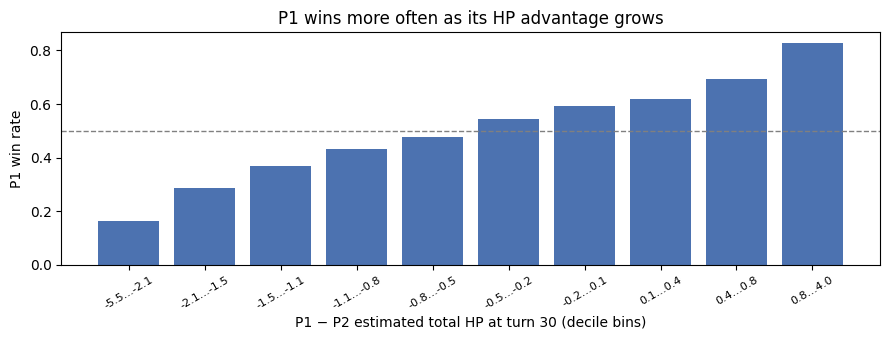

In [18]:
hp_bins = pd.qcut(train_tables['base']['diff_hp_total_est'], 10, duplicates='drop')
win_rate = pd.Series(y).groupby(hp_bins.values, observed=True).mean()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(len(win_rate)), win_rate.values, color='#4C72B0')
ax.axhline(0.5, color='grey', linestyle='--', linewidth=1)
ax.set_xticks(range(len(win_rate)))
ax.set_xticklabels([f'{b.left:.1f}…{b.right:.1f}' for b in win_rate.index], rotation=30, fontsize=8)
ax.set_xlabel('P1 − P2 estimated total HP at turn 30 (decile bins)')
ax.set_ylabel('P1 win rate')
ax.set_title('P1 wins more often as its HP advantage grows')
plt.tight_layout()
plt.show()

The relationship is strong and steady, but even in the best bin P1 doesn't win every game, and in the worst it still wins some. That is the limit of what the battle state at turn 30 can tell us, and the reason the extra feature groups target information this number doesn't contain.

## 8. Model: matrices, LightGBM, logistic regression, blend

**From features to matrices.** `build_matrices(groups, …)` builds the inputs for one training set and one prediction set:

1. It concatenates the baseline with the chosen feature groups. For `fp` it computes the fingerprint out-of-fold, as described in 6.7.
2. Numeric columns form a **dense** matrix.
3. Each text column goes through a `CountVectorizer`, which creates one column per species or move that appears in at least 5 training battles. Moves are counted; everything else is 0/1. The vocabulary is learned from the training set only. The result is a **sparse** matrix of about 1,700 columns.

**Two different models.**

- **LightGBM** (gradient-boosted decision trees) builds many small trees, each correcting the previous ones. It captures interactions such as "ahead on HP, but P2 has Spikes up", handles missing values, and doesn't need scaling. Missing values are encoded as −999. Our settings favour many small, randomised trees: 7 leaves, 30% of columns per tree, 80% of rows per tree, learning rate 0.02.
- **Logistic regression** is a linear model on standardised numeric features plus the sparse columns. With strong regularisation (C = 0.01) it gives smooth, stable estimates for the thousands of sparse species and move columns. It is weaker on its own but makes different mistakes from the trees.

**Blend.** The final probability is `0.7 × LightGBM + 0.3 × logistic regression`, and we predict "P1 wins" when it is above 0.5. The weight was chosen by trying 0, 0.1, …, 1 on out-of-fold predictions (Section 9).

In [19]:
def build_matrices(groups, fit_idx, pred_tables, pred_keys, pred_idx):
    """Build model inputs.
    fit_idx:   which training battles to fit on
    pred_*:    which battles to predict (training battles in CV, test battles at the end)
    Returns dense and sparse matrices for both sets, plus the column names."""
    fit_parts = [train_tables['base'].iloc[fit_idx].reset_index(drop=True)]
    pred_parts = [pred_tables['base'].iloc[pred_idx].reset_index(drop=True)]
    for group in groups:
        if group == 'fp':
            fit_fp, pred_fp = fingerprint_features(train_keys.iloc[fit_idx].reset_index(drop=True), y[fit_idx],
                                                   pred_keys.iloc[pred_idx].reset_index(drop=True))
            fit_parts.append(fit_fp)
            pred_parts.append(pred_fp)
        else:
            fit_parts.append(train_tables[group].iloc[fit_idx].reset_index(drop=True))
            pred_parts.append(pred_tables[group].iloc[pred_idx].reset_index(drop=True))
    fit_df = pd.concat(fit_parts, axis=1)
    pred_df = pd.concat(pred_parts, axis=1)

    text_columns = [c for c in fit_df.columns if c.startswith('_')]
    dense_columns = [c for c in fit_df.columns if not c.startswith('_')]

    # one sparse column per species/move seen in at least 5 training battles
    fit_text, pred_text, names = [], [], list(dense_columns)
    for col in text_columns:
        count_moves = col in ('_p1_moves', '_p2_moves')     # moves are counted, everything else is 0/1
        vectorizer = CountVectorizer(token_pattern=r'\S+', min_df=5, binary=not count_moves)
        vectorizer.fit(fit_df[col].fillna(''))
        fit_text.append(vectorizer.transform(fit_df[col].fillna('')))
        pred_text.append(vectorizer.transform(pred_df[col].fillna('')))
        names += [f'{col}:{token}' for token in vectorizer.get_feature_names_out()]

    fit_text = sp.hstack(fit_text).tocsr()
    pred_text = sp.hstack(pred_text).tocsr()
    return fit_df[dense_columns], pred_df[dense_columns], fit_text, pred_text, names


def lgbm_matrix(dense, text):
    """LightGBM input: dense columns (missing -> -999) next to the sparse text columns."""
    dense_part = sp.csr_matrix(dense.fillna(-999).values.astype(np.float32))
    return sp.hstack([dense_part, text]).tocsr().astype(np.float32)


def logreg_matrix(dense, text, scaler):
    """Logistic regression input: standardised dense columns (missing -> 0) next to the text columns."""
    return sp.hstack([scaler.transform(dense.fillna(0)), text]).tocsr()

In [20]:
def train_blend(dense_fit, text_fit, y_fit, dense_pred, text_pred, seeds):
    """Train logistic regression + LightGBM and return the blended P(P1 wins) and the LightGBM models."""
    # logistic regression
    scaler = StandardScaler().fit(dense_fit.fillna(0))
    logreg = LogisticRegression(C=LOGREG_C, max_iter=5000)
    logreg.fit(logreg_matrix(dense_fit, text_fit, scaler), y_fit)
    p_logreg = logreg.predict_proba(logreg_matrix(dense_pred, text_pred, scaler))[:, 1]

    # LightGBM, one model per seed, averaged
    X_fit = lgbm_matrix(dense_fit, text_fit)
    X_pred = lgbm_matrix(dense_pred, text_pred)
    models = []
    predictions = []
    for seed in seeds:
        model = lgb.LGBMClassifier(random_state=seed, **LGBM_PARAMS)
        model.fit(X_fit, y_fit)
        models.append(model)
        predictions.append(model.predict_proba(X_pred)[:, 1])
    p_lgbm = np.mean(predictions, axis=0)

    return LGBM_WEIGHT * p_lgbm + (1 - LGBM_WEIGHT) * p_logreg, models

## 9. How the design was chosen: experiments and results

**Validation method.** All decisions were made with 5-fold stratified cross-validation, repeated twice with different random splits, so 10 train/validation splits. Within one experiment, all variants use the **same splits**, so differences between them come from the features or settings, not from luck in the split. We report:

- **Accuracy**, the competition metric;
- **Log-loss**, which scores the predicted probabilities rather than just which side of 50% they fall on. It is much less noisy than accuracy on 2,000 validation battles, so it was our main guide;
- **"Folds better"**: in how many of the 10 splits a variant beat the reference. A real improvement should win most of them.

For speed, the experiments used LightGBM alone with 15 leaves and 800 rounds. The blend was tuned afterwards.

### Experiment 1: adding each feature group to the baseline

| Variant | Accuracy | Change | Log-loss | Change | Log-loss better in |
|---|---|---|---|---|---|
| Baseline | 68.13% | — | 0.5841 | — | — |
| + fingerprint | 68.20% | +0.07 | 0.5811 | −0.0030 | 10/10 |
| + P2 inference | 68.12% | −0.02 | 0.5835 | −0.0007 | 7/10 |
| + win conditions | 68.27% | +0.14 | 0.5812 | −0.0029 | 9/10 |
| + hidden faints | 68.08% | −0.05 | 0.5829 | −0.0012 | 6/10 |
| + items | 67.95% | −0.18 | 0.5840 | −0.0001 | 4/10 |
| + trajectory | 68.06% | −0.07 | 0.5853 | +0.0012 | 4/10 |
| **+ all six** | **68.49%** | **+0.36** | **0.5771** | **−0.0070** | **10/10** |

The fingerprint and the win conditions help clearly on their own. P2 inference and hidden faints help little alone, mostly because they overlap with the baseline's HP features. Together the groups give a clear improvement in every split: they interact, so they should be judged together.

### Experiment 2: removing one group at a time from the full model

New random splits, so the reference is slightly different. A positive change means the model is **worse** without that group.

| Variant | Accuracy | Log-loss | Change vs. all six | Better without it in |
|---|---|---|---|---|
| All six | 68.80% | 0.5768 | — | — |
| − fingerprint | 68.47% | 0.5806 | +0.0038 | 1/10 |
| − P2 inference | 68.77% | 0.5781 | +0.0013 | 2/10 |
| − win conditions | 68.64% | 0.5800 | +0.0032 | 0/10 |
| − hidden faints | 68.56% | 0.5779 | +0.0011 | 2/10 |
| − items | 68.72% | 0.5775 | +0.0007 | 3/10 |
| − trajectory | 68.79% | 0.5763 | −0.0005 | 5/10 |

Removing any group except trajectory makes the model worse in most splits. Trajectory is neutral (5 of 10 either way), so it is harmless to keep. We kept all six.

### Experiment 3: model settings and blend weight

On the same splits, with all six groups:

| Model | Accuracy | Log-loss |
|---|---|---|
| LightGBM, 15 leaves, 30% columns | 68.80% | 0.5768 |
| LightGBM, 31 leaves | 68.62% | 0.5798 |
| LightGBM, 15 leaves, 15% columns | 68.77% | 0.5768 |
| **LightGBM, 7 leaves, 1,500 rounds** | 68.67% | **0.5762** |
| Logistic regression, C = 0.01 | 68.01% | 0.5843 |
| Logistic regression, C = 0.02 | 67.86% | 0.5881 |
| Logistic regression, C = 0.05 | 67.39% | 0.5954 |

| LightGBM weight in the blend | 0 | 0.3 | 0.5 | 0.6 | **0.7** | 0.8 | 1 |
|---|---|---|---|---|---|---|---|
| Accuracy | 68.01% | 68.75% | 68.78% | 68.94% | **68.98%** | 68.95% | 68.67% |
| Log-loss | 0.5843 | 0.5766 | 0.5741 | 0.5736 | **0.5735** | 0.5739 | 0.5762 |

LightGBM settings barely matter (all within 0.004 log-loss), so further tuning would not help. The blend beats both models alone; the best weight is 0.7, and the curve is flat between 0.6 and 0.8, so the choice is not fragile. Because the weight was picked on the same predictions it is scored on, 68.98% is slightly optimistic; Section 10 re-measures the final setup on new splits.

### Summary of the progression

| Step | CV accuracy | CV log-loss |
|---|---|---|
| Coin flip | 50% | 0.693 |
| Baseline (LightGBM) | 68.1% | 0.584 |
| + six feature groups | 68.5–68.8% | 0.577 |
| + tuned blend (final) | about 69.0% | 0.5735 |

**Rerunning the experiments.** The cell below reproduces Experiments 1 and 2 when `RUN_EXPERIMENTS = True`. It takes about 30 minutes, because every variant is trained on 10 splits.

In [21]:
# settings used during the experiments (LightGBM only, a bit faster than the final model)
EXPERIMENT_LGBM = dict(LGBM_PARAMS, num_leaves=15, n_estimators=800)


def compare_variants(variants, reference, repeats=2, first_seed=0):
    """Score several feature-group combinations on the same CV splits.
    variants: {name: list of groups}. Differences are measured against the 'reference' variant."""
    scores = {name: {'acc': [], 'll': []} for name in variants}
    for repeat in range(repeats):
        splits = StratifiedKFold(5, shuffle=True, random_state=first_seed + repeat).split(np.zeros(len(y)), y)
        for fit_idx, val_idx in splits:
            for name, groups in variants.items():
                dense_fit, dense_val, text_fit, text_val, _ = build_matrices(groups, fit_idx, train_tables,
                                                                             train_keys, val_idx)
                model = lgb.LGBMClassifier(random_state=repeat, **EXPERIMENT_LGBM)
                model.fit(lgbm_matrix(dense_fit, text_fit), y[fit_idx])
                p = model.predict_proba(lgbm_matrix(dense_val, text_val))[:, 1]
                scores[name]['acc'].append(((p > 0.5) == y[val_idx]).mean())
                scores[name]['ll'].append(log_loss(y[val_idx], p))
        log(f'repeat {repeat} done')

    ref_acc = np.array(scores[reference]['acc'])
    ref_ll = np.array(scores[reference]['ll'])
    rows = []
    for name, s in scores.items():
        acc, ll = np.array(s['acc']), np.array(s['ll'])
        rows.append({'variant': name, 'accuracy': acc.mean(), 'd_accuracy': (acc - ref_acc).mean(),
                     'logloss': ll.mean(), 'd_logloss': (ll - ref_ll).mean(),
                     'logloss_better': f'{(ll < ref_ll).sum()}/{len(ll)}'})
    return pd.DataFrame(rows).round(4)


if RUN_EXPERIMENTS:
    # Experiment 1: baseline + one group at a time, and + all groups
    experiment_1 = {'baseline': []}
    for group in FEATURE_GROUPS:
        experiment_1['+ ' + group] = [group]
    experiment_1['+ all six'] = FEATURE_GROUPS
    display(compare_variants(experiment_1, 'baseline', first_seed=0))

    # Experiment 2: all groups minus one at a time
    experiment_2 = {'all six': FEATURE_GROUPS}
    for group in FEATURE_GROUPS:
        experiment_2['- ' + group] = [g for g in FEATURE_GROUPS if g != group]
    display(compare_variants(experiment_2, 'all six', first_seed=100))
else:
    print('Experiments skipped (RUN_EXPERIMENTS = False). Recorded results are in the tables above.')

Experiments skipped (RUN_EXPERIMENTS = False). Recorded results are in the tables above.


## 10. Cross-validation check of the final setup

Here we measure the exact final pipeline, blend included, on 5 new splits that weren't used to make any decision. Each fold uses one LightGBM seed instead of five, to save time, so if anything this slightly underestimates the final model.

In [22]:
if RUN_CV:
    accuracies, loglosses = [], []
    splits = StratifiedKFold(5, shuffle=True, random_state=42).split(np.zeros(len(y)), y)
    for fold, (fit_idx, val_idx) in enumerate(splits):
        dense_fit, dense_val, text_fit, text_val, _ = build_matrices(FEATURE_GROUPS, fit_idx, train_tables,
                                                                     train_keys, val_idx)
        p, _ = train_blend(dense_fit, text_fit, y[fit_idx], dense_val, text_val, seeds=[0])
        accuracies.append(((p > 0.5) == y[val_idx]).mean())
        loglosses.append(log_loss(y[val_idx], p))
        log(f'fold {fold}: accuracy {accuracies[-1]:.4f} | log-loss {loglosses[-1]:.4f}')
    log(f'CV accuracy {np.mean(accuracies):.4f} ± {np.std(accuracies):.4f} | log-loss {np.mean(loglosses):.4f}')
else:
    print('CV check skipped (RUN_CV = False).')

[   50s] fold 0: accuracy 0.6860 | log-loss 0.5771
[   59s] fold 1: accuracy 0.6890 | log-loss 0.5688
[   68s] fold 2: accuracy 0.6910 | log-loss 0.5672
[   78s] fold 3: accuracy 0.7064 | log-loss 0.5694
[   87s] fold 4: accuracy 0.6924 | log-loss 0.5717
[   87s] CV accuracy 0.6930 ± 0.0070 | log-loss 0.5708


The spread between folds (about ±0.8 points) is a reminder of how noisy accuracy is on 2,000 battles. It's also a guide to the leaderboard: with 5,000 test battles, the test score has a margin of roughly ±0.65 points around the true accuracy, more if the public leaderboard uses only part of the test set.

## 11. Final model and submission

The final model is trained once on **all** 9,983 de-duplicated training battles. The cross-validation models above are only for measurement and are discarded. LightGBM is trained with 5 seeds and averaged.

After predicting, the test battles that are identical to a training battle get the known training label instead of the prediction (see Section 4). Finally we check the file: 5,000 rows, the same IDs in the same order as `sample_submission.csv`, values 0 or 1, and a predicted win rate close to 50%.

In [23]:
log('training the final model on all training battles ...')
all_train = np.arange(len(y))
all_test = np.arange(len(test_raw))
dense_train, dense_test, text_train, text_test, feature_names = build_matrices(
    FEATURE_GROUPS, all_train, test_tables, test_keys, all_test)
p_test, final_models = train_blend(dense_train, text_train, y, dense_test, text_test, seeds=range(N_SEEDS))
predictions = (p_test > 0.5).astype(int)

# test battles identical to a training battle: use the known result
known_result = {battle_key(b): int(b['player_won']) for b in train_raw}
n_copied = n_changed = 0
for i, battle in enumerate(test_raw):
    key = battle_key(battle)
    if key in known_result:
        n_copied += 1
        if predictions[i] != known_result[key]:
            n_changed += 1
        predictions[i] = known_result[key]

submission = pd.DataFrame({'battle_id': [b['battle_id'] for b in test_raw], 'player_won': predictions})
submission.to_csv(os.path.join(OUT_DIR, 'submission.csv'), index=False)
log(f'saved submission.csv {submission.shape} | predicted P1 win rate {predictions.mean():.3f} | '
    f'{n_copied} labels copied from duplicate train battles ({n_changed} differed from the prediction)')

[   87s] training the final model on all training battles ...
[  139s] saved submission.csv (5000, 2) | predicted P1 win rate 0.513 | 8 labels copied from duplicate train battles (1 differed from the prediction)


In [24]:
sample_path = os.path.join(DATA_DIR, 'sample_submission.csv')
if os.path.exists(sample_path):
    sample = pd.read_csv(sample_path)
    assert len(submission) == len(sample), 'wrong number of rows'
    assert (submission['battle_id'].values == sample['battle_id'].values).all(), 'IDs do not match'
    print('IDs match sample_submission.csv')
assert submission['player_won'].isin([0, 1]).all(), 'predictions must be 0 or 1'
print('rows:', len(submission), '| share predicted as P1 wins:', round(submission['player_won'].mean(), 3))
display(submission.head())

IDs match sample_submission.csv
rows: 5000 | share predicted as P1 wins: 0.513


,battle_id,player_won
0,0,1
1,1,1
2,2,0
3,3,0
4,4,1


## 12. What the model relies on

Below are the 20 features with the largest share of LightGBM's total **gain**, averaged over the 5 final models. Gain measures how much a feature improved the training objective when the trees split on it. High gain means the model uses a feature a lot. It doesn't by itself prove the feature improves predictions; that is what the experiments of Section 9 measure. The trajectory features are an example: they rank high here but were neutral in Experiment 2, because they re-express HP information the model already has.

Sparse columns appear as `column:token`, for example `_p1_moves:spikes`.

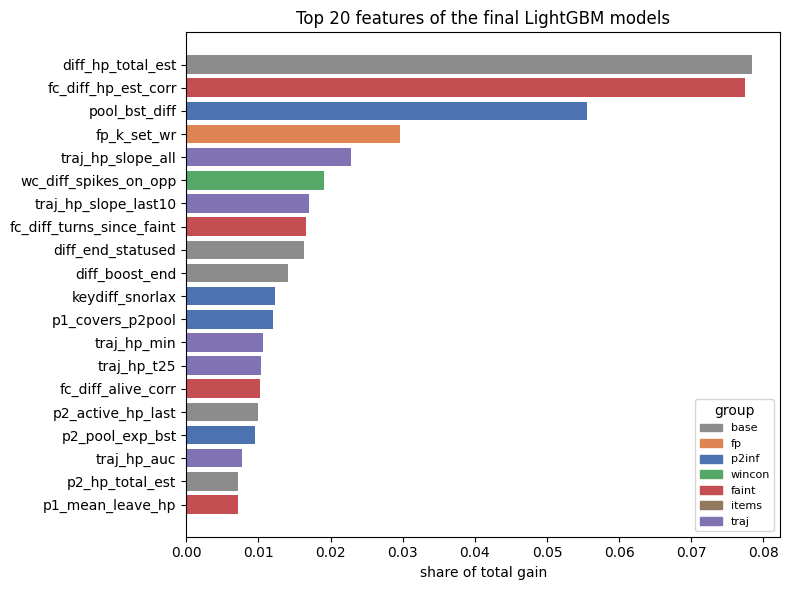

,share of total gain by group
base,0.487
p2inf,0.175
faint,0.140
traj,0.093
wincon,0.056
fp,0.038
items,0.011


In [25]:
# average gain over the 5 final LightGBM models, as a share of the total
gains = np.mean([m.booster_.feature_importance('gain') for m in final_models], axis=0)
importance = pd.Series(gains / gains.sum(), index=feature_names).sort_values(ascending=False)

# which group each column belongs to
column_group = {}
for group, table in train_tables.items():
    for col in table.columns:
        column_group[col] = group

def group_of(name):
    if name.startswith('fp_'):
        return 'fp'
    return column_group.get(name.split(':')[0], '?')   # 'col:token' -> 'col'

GROUP_COLORS = {'base': '#8C8C8C', 'fp': '#DD8452', 'p2inf': '#4C72B0', 'wincon': '#55A868',
                'faint': '#C44E52', 'items': '#937860', 'traj': '#8172B3'}

top = importance.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=[GROUP_COLORS[group_of(n)] for n in top.index])
ax.set_xlabel('share of total gain')
ax.set_title('Top 20 features of the final LightGBM models')
legend_boxes = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
ax.legend(legend_boxes, GROUP_COLORS.keys(), loc='lower right', fontsize=8, title='group')
plt.tight_layout()
plt.show()

by_group = importance.groupby([group_of(n) for n in importance.index]).sum().sort_values(ascending=False)
display(by_group.round(3).to_frame('share of total gain by group'))

The pattern is consistent with the experiments. HP-based state dominates: the baseline HP difference and its corrected version from the hidden-faints group are almost tied at the top. P2's estimated remaining strength (`pool_bst_diff`, from the P2-inference group) is third, and the species-set fingerprint win rate is fourth. Spikes is the strongest single win condition.

The group totals also show why gain alone is a poor guide. The win-condition group has only about 6% of the gain, yet removing it hurt the model in all 10 splits of Experiment 2. Its features are rarely non-zero, so they are used in few splits, but when they matter they matter a lot. The trajectory group is the opposite case: about 9% of the gain, but neutral in the experiments.

## 13. Limitations and possible next steps

**Limitations.**

- **Hidden information.** P2's unseen Pokémon, P2's items and every Pokémon's unrevealed moves are unknown. The co-occurrence estimate of P2's team is a population average, not knowledge of this particular player.
- **The game is unfinished.** Battles usually last well beyond 30 turns, so many are genuinely open at turn 30. A large part of the remaining error is probably irreducible from this data.
- **Hidden faints are a heuristic.** "Left at ≤15% HP and never returned" misses some faints and wrongly counts some Pokémon that were simply kept in reserve.
- **Fingerprint coverage.** Only about 11% of test battles share an exact team with a training battle, so the player-skill signal helps a minority of battles.
- **Noise.** With 5,000 test battles, leaderboard differences under about one point between two submissions are within noise.